# tugas mandiri 1 pemograman paralel
## Fathiya Dhiyaul Izzaty_2411513037

# 1. Klasifikasi Flynn

### Untuk masing-masing skenario berikut, tentukan kategori Flynn (SISD/SIMD/MISD/MIMD) beserta alasannya.
### a. Operasi arr+arr pada NumPy array.
### b. Program Python biasa (threading/multiprocessing) yang membaca file lalu memproses baris demi baris.
### c. Cluster komputer yang masing-masing node menjalankan simulasi cuaca berbeda secara independen.

## JAWAB:
### a. arr * 2 pada NumPy array → SIMD Satu instruksi diterapkan pada banyak data secara bersamaan.
### b. Python membaca file baris demi baris → SISD Data diproses satu per satu secara berurutan.
### c. Cluster menjalankan simulasi cuaca berbeda → MIMD Setiap node menjalankan instruksi dan mengolah data yang berbeda secara bersamaan.

## 2. Analisis Amdahl
### Sebuah aplikasi memiliki proporsi paralel P = 0.85.
#### a. Hitung speedup teoritis untuk N = 2, 4, 8, 16, 32, 64 (gunakan fungsi amdahl_speedup di atas).
#### b. Buat plot speedup vs N.
#### c. Pada N berapa penambahan prosesor mulai memberikan manfaat yang sangat kecil ("diminishing returns")? Jelaskan alasan kalian.

## JAWAB

Hasil Speedup Hukum Amdahl
N = 2  →  Speedup = 1.7391x
N = 4  →  Speedup = 2.7586x
N = 8  →  Speedup = 3.9024x
N = 16  →  Speedup = 4.9231x
N = 32  →  Speedup = 5.6637x
N = 64  →  Speedup = 6.1244x


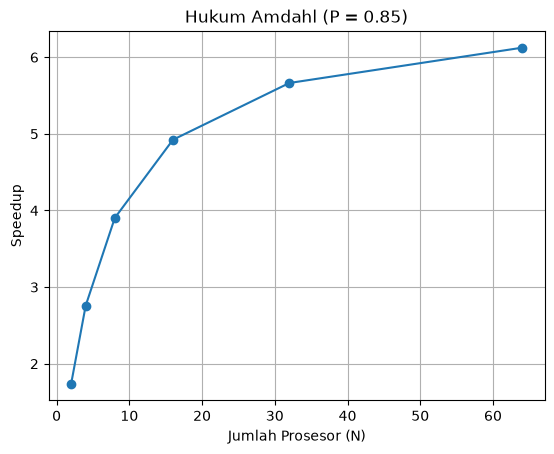

In [3]:

### a. Hitung speedup teoritis
import numpy as np
import matplotlib.pyplot as plt

# Nilai P
P = 0.85

# Jumlah prosesor
N = np.array([2, 4, 8, 16, 32, 64])

# Rumus Hukum Amdahl
S = 1 / ((1 - P) + (P / N))

# Menampilkan hasil
print("Hasil Speedup Hukum Amdahl")
for i in range(len(N)):
    print(f"N = {N[i]}  →  Speedup = {S[i]:.4f}x")

# Membuat grafik
plt.plot(N, S, marker='o')
plt.title("Hukum Amdahl (P = 0.85)")
plt.xlabel("Jumlah Prosesor (N)")
plt.ylabel("Speedup")
plt.grid()
plt.show()

## c.  Pada N berapa penambahan prosesor mulai memberikan manfaat yang sangat kecil ("diminishing returns")? Jelaskan alasan kalian.
Penambahan prosesor mulai memberikan manfaat yang semakin kecil (diminishing returns) pada N = 16. Hal ini terlihat dari peningkatan speedup yang mulai melambat ketika jumlah prosesor ditambah. Pada N = 16 diperoleh speedup sebesar 5,0794×, kemudian pada N = 32 hanya meningkat menjadi 5,9326× dan pada N = 64 menjadi 6,5543×. Kondisi ini terjadi karena terdapat 15% bagian program yang tidak dapat diparalelkan, sehingga penambahan prosesor tidak lagi memberikan peningkatan kinerja yang besar. Jadi, semakin banyak prosesor yang digunakan, speedup akan semakin mendekati batas maksimum teoritis sebesar 6,67×.

## 3. Benchmark Mandiri Ambil salah satu fungsi **CPU-bound** buatan sendiri (boleh modifikasi `hitung_prima`, atau buat fungsi lain seperti menghitung deret Fibonacci secara rekursif). Ukur waktu eksekusinya untuk **minimal 4 ukuran input berbeda** menggunakan`time.perf_counter()` dan `timeit`, lalu bandingkan hasil keduanya dalam satu tabel/plot.

## JAWAB:

In [4]:
import time
import timeit

def hitung_prima(n):
  count = 0
  for i in range(2, n):
    is_prime = True
    for j in range(2, int(i**0.5) + 1):
      if i % j == 0:
        is_prime = False
        break
    if is_prime:
      count += 1
  return count

input_sizes = [1000, 5000, 10000, 20000]

print(f"{'Ukuran Input (N)':<18} | {'perf_counter() (s)':<20} | {'timeit (s)':<15}")
print("-" * 60)

for size in input_sizes:
  # 1. Menggunakan time.perf_counter()
  t0 = time.perf_counter()
  hitung_prima(size)
  t1 = time.perf_counter()
  waktu_perf = t1 - t0

  # 2. Menggunakan timeit
  waktu_timeit = timeit.timeit(lambda: hitung_prima(size), number=1)

  print(f"{size:<18} | {waktu_perf:<20.6f} | {waktu_timeit:<15.6f}")

Ukuran Input (N)   | perf_counter() (s)   | timeit (s)     
------------------------------------------------------------
1000               | 0.000397             | 0.000388       
5000               | 0.002520             | 0.002638       
10000              | 0.005669             | 0.007323       
20000              | 0.016546             | 0.014490       


## 4. Refleksi Singkat Menurut kalian, kapan Hukum Amdahl lebih relevan digunakan dibanding Hukum Gustafson, dan sebaliknya? Berikan satu contoh kasus nyata untuk masing-masing
## JAWAB:

Hukum Amdahl lebih relevan ketika ukuran masalah tetap dan jumlah prosesor ditambah. Hukum ini menunjukkan bahwa bagian program yang tidak dapat diparalelkan membatasi peningkatan kinerja. Sedangkan Hukum Gustafson lebih sesuai untuk ukuran masalah yang semakin besar seiring bertambahnya prosesor.